# Analysis of results

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


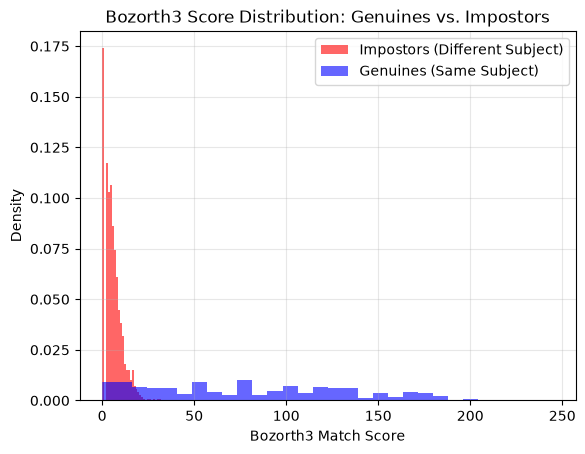

In [3]:
df = pd.read_csv('../bozorth_results.csv')
genuines = df[df['type'] == 'genuine']['score']
impostors = df[df['type'] == 'impostor']['score']

# Plot histograms with transparency to see overlaps
plt.hist(impostors, bins=30, alpha=0.6, color='red', label='Impostors (Different Subject)', density=True)
plt.hist(genuines, bins=30, alpha=0.6, color='blue', label='Genuines (Same Subject)', density=True)

plt.title('Bozorth3 Score Distribution: Genuines vs. Impostors')
plt.xlabel('Bozorth3 Match Score')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

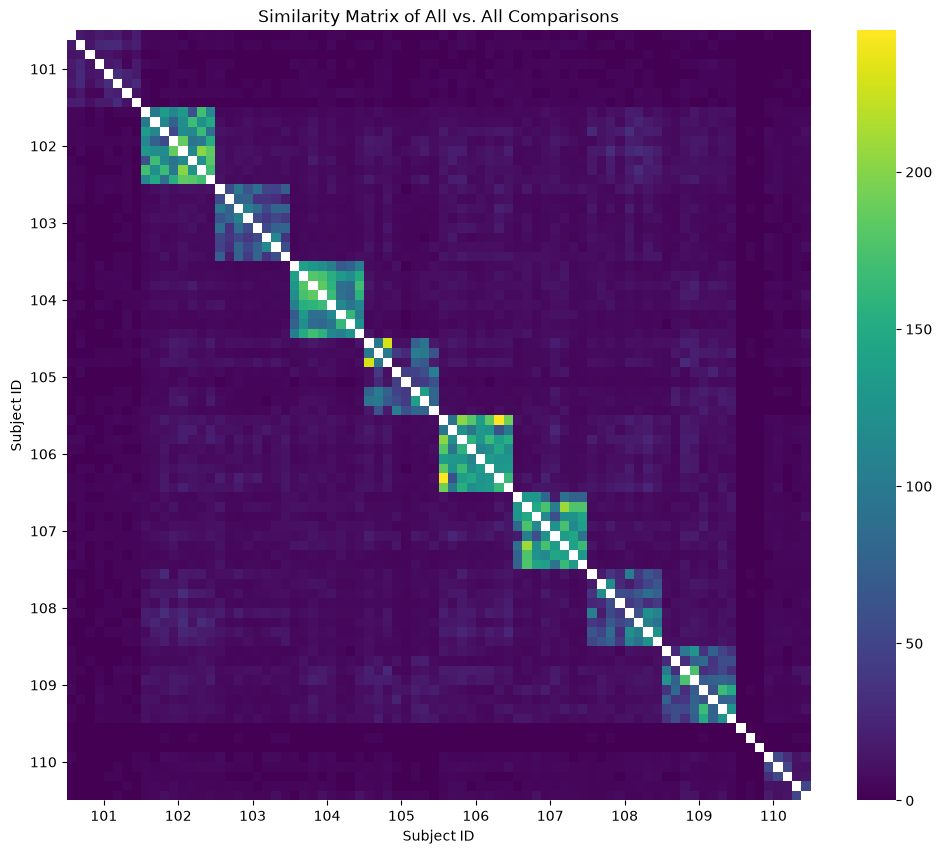

In [5]:
all_images = sorted(list(set(df['img1'].unique().tolist() + df['img2'].unique().tolist())))

# Initialize an empty matrix (DataFrame) filled with NaNs
matrix = pd.DataFrame(index=all_images, columns=all_images, dtype=float)

# Fill the matrix with the bozorth3 scores
for _, row in df.iterrows():
    matrix.at[row['img1'], row['img2']] = row['score']
    # Mirror the score so the matrix is symmetrical for visualization
    matrix.at[row['img2'], row['img1']] = row['score'] 

plt.figure(figsize=(12, 10))

# Turn off Seaborn's default labels so we can apply custom centered ones
sns.heatmap(matrix, cmap='viridis', xticklabels=False, yticklabels=False)

# Calculate center positions for each of the 10 subjects (blocks of 8)
# The centers will be at indices 4, 12, 20... up to 76
tick_positions = np.arange(4, 80, 8)

# Extract just the subject ID (e.g., "101") for each of those positions
subject_labels = [all_images[i].split('_')[0] for i in tick_positions]

# Apply the custom ticks to the axes
plt.xticks(tick_positions, subject_labels, rotation=0, fontsize=10)
plt.yticks(tick_positions, subject_labels, rotation=0, fontsize=10)

plt.title('Similarity Matrix of All vs. All Comparisons')
plt.xlabel('Subject ID')
plt.ylabel('Subject ID')
plt.show()

Fingerprint 101 and 110 are problematic, since the images fail to reflect similarity.